# Part A — SRR (Specular Reflection Removal) preprocessing pipeline

A specular-reflection-removal preprocessing pipeline for cervical colposcopy
images. The pipeline detects specular glare dots on the **un-sharpened** image
(sharpening creates fake high-contrast spots that look like glare), drops
connected components larger than 1 % of the FOV area (so acetowhite
epithelium is not flagged), fills small holes per connected component (with a
cap on hole area so a loop of glare dots does not fill the tissue inside it),
dilates the mask, then inpaints the glare pixels on the **sharpened** image
with Navier-Stokes inpainting and an optional bilateral touch-up inside the
mask only.

## Detector (per connected component, ring-contrast test)

The spec'd white top-hat with kernel 15 only flags the **rim** of any blob
wider than 15 px (the top-hat response is the original minus the opened
image, and the opening erases the blob interior). To handle blobs of any
size up to the area cap, we use a **per-connected-component ring-contrast
test**:

1. Candidate pixels: `(V > V_THR) & (S < S_THR)` inside the FOV.
2. For each connected component of the candidate mask:
   - Compute the mean V inside the component.
   - Compute the **median** V of the ring `SRR_RING_WIDTH` px just outside
     the component, **excluding any other raw_mask pixels** (so a cluster
     of glare dots does not lift the ring brightness and fail the test).
   - If `mean_V_inside - median_V_ring >= SRR_RING_CONTRAST`, flag the
     component as glare.
3. Drop components larger than `MAX_BLOB_FRAC * FOV_area` (protects
   acetowhite — but acetowhite also fails the ring test because its ring is
   equally bright, so the area cap is a secondary safety net).

This works for any blob size up to the area cap, and bright acetowhite
epithelium fails the ring test (ring is bright too) so it is not masked.

## Pipeline overview

* Step 1 — Unsharp-mask sharpen (carried over from Step 1, identical to the
  other 25 techniques so the `cache_hash` matches).
* Step 2 — Specular reflection removal:
  1. Detect on the un-sharpened image with the per-CC ring-contrast test
     above.
  2. Per connected component: fill holes **with an area cap**
     (`SRR_HOLE_MAX_FRAC * FOV_area`), then drop components larger than
     `MAX_BLOB_FRAC * FOV_area`.
  3. Morphological close + dilate (3×3 ellipse, 2 iterations).
  4. `cv2.inpaint` (Navier-Stokes, radius 5 for blobs >10 px, radius 3
     otherwise) on the **sharpened** image inside the mask. For very large
     blobs, fall back to median-of-ring fill.
  5. Optional bilateral filter applied only inside the mask.
  6. Pixels outside the mask stay bit-identical to the input.

## Output

The pipeline returns a **uint8 RGB image** (same shape as the input). There
is no stochastic step, so the random seed is irrelevant for SRR itself; the
seed is only used for the smoke test and the paired-glare recovery table.

## What this notebook does NOT claim

* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.
* The dHash clustering and FOV definition are kept identical to the other
  25 techniques so SRR can be merged with them.
* **Dataset note**: the 128 frames are about 16 unique images from 1
  patient (the v2 byte-level SHA-256 dedupe gave 128→16). The 128 frames
  match the frozen `cache_hash`, so they are kept for cross-technique
  comparability.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, glob, json, math, random, warnings, platform, hashlib
from collections import defaultdict

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / PNG artefacts
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(os.path.join(SAVE_DIR, 'srr_outputs'), exist_ok=True)
os.makedirs(os.path.join(SAVE_DIR, 'masks'), exist_ok=True)

print(f"\nSRR Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



SRR Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 — Configuration (SRR only) + provenance hash
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
DATASET_ROOT   = "C:/CER/dataset"      # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"     # <-- single class folder
CLASSES        = ["invasive cancer"]

# ---- Sharpen (Step 1, shared across all 26 notebooks) ----
# These values come from Step 1 and MUST match the other 25 notebooks so the
# cache_hash matches. Do not change them here unless you change them in all
# 26 notebooks and re-run.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- SRR config (all in one cell) ----
SRR_V_THR           = 250      # V threshold for glare candidate pixels
SRR_S_THR           = 25       # S threshold (low saturation = white)
SRR_RING_CONTRAST   = 30       # ring contrast: inside_mean - ring_median >= this
SRR_RING_WIDTH      = 3        # ring width (px) outside each CC for the test
SRR_MAX_BLOB_FRAC   = 0.01     # drop glare blobs > 1% of FOV area (protects acetowhite)
SRR_HOLE_MAX_FRAC   = 0.001    # per-CC hole-fill area cap (0.1% of FOV); protects
                               #   tissue inside a loop of glare dots
SRR_CLOSE_KSIZE     = 5        # morphological close kernel size (odd)
SRR_DILATE          = 2        # dilation iterations (3x3 ellipse x 2 iters)
SRR_INPAINT_METHOD  = "NS"     # "NS" = Navier-Stokes, "TELEA" = Telea
SRR_INPAINT_RADIUS_SMALL = 3   # inpaint radius for blobs <= 10 px
SRR_INPAINT_RADIUS_LARGE = 5   # inpaint radius for blobs > 10 px
SRR_LARGE_BLOB_PX   = 10       # blob diameter threshold (px) for radius switch
SRR_MEDIAN_RING_FALLBACK = True  # use median-of-ring fill for very large blobs
USE_BILATERAL_POST  = True     # bilateral filter inside the mask after inpaint

# ---- DEV_MODE: smoke-test the whole notebook on synthetic data ----
# Set to True ONLY to smoke-test the notebook end-to-end without the real
# dataset. In DEV_MODE the cache_hash assert is skipped (synthetic data does
# not match the frozen hash). The real run MUST use DEV_MODE=False.
DEV_MODE = False

# ---- Validation batch ----
SUBSET_PER_CLASS = None        # None = all images

# Global flag set by the loader
SYNTHETIC_MODE = False

# ---- Provenance: hash of the SRR config constants ----
# cache_hash only covers the input images; this hash covers the SRR config
# so any change to the detector/inpaint parameters is recorded in every CSV.
_SRR_CONFIG_KEYS = [
    "SRR_V_THR", "SRR_S_THR", "SRR_RING_CONTRAST",
    "SRR_RING_WIDTH", "SRR_MAX_BLOB_FRAC", "SRR_HOLE_MAX_FRAC",
    "SRR_CLOSE_KSIZE", "SRR_DILATE",
    "SRR_INPAINT_METHOD", "SRR_INPAINT_RADIUS_SMALL", "SRR_INPAINT_RADIUS_LARGE",
    "SRR_LARGE_BLOB_PX", "SRR_MEDIAN_RING_FALLBACK", "USE_BILATERAL_POST",
    "APPLY_SHARPEN", "SHARPEN_AMOUNT", "SHARPEN_KSIZE", "IMG_SIZE",
]
_srr_cfg_str = "|".join(f"{k}={globals()[k]}" for k in _SRR_CONFIG_KEYS)
SRR_CONFIG_HASH = hashlib.md5(_srr_cfg_str.encode()).hexdigest()[:12]

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  SRR: V>{SRR_V_THR}, S<{SRR_S_THR}, ring_w={SRR_RING_WIDTH}, "
      f"ring_contrast={SRR_RING_CONTRAST}, max_blob={SRR_MAX_BLOB_FRAC}*FOV, "
      f"hole_max={SRR_HOLE_MAX_FRAC}*FOV, "
      f"close_k={SRR_CLOSE_KSIZE}, dilate={SRR_DILATE} (3x3 ellipse x {SRR_DILATE} iters), "
      f"inpaint={SRR_INPAINT_METHOD} (r{SRR_INPAINT_RADIUS_SMALL}<=10px, r{SRR_INPAINT_RADIUS_LARGE}>10px), "
      f"bilateral_post={USE_BILATERAL_POST}")
print(f"  SRR_CONFIG_HASH = {SRR_CONFIG_HASH}  (added to every CSV for provenance)")
print(f"  DEV_MODE = {DEV_MODE}")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  SRR: V>250, S<25, ring_w=3, ring_contrast=30, max_blob=0.01*FOV, hole_max=0.001*FOV, close_k=5, dilate=2 (3x3 ellipse x 2 iters), inpaint=NS (r3<=10px, r5>10px), bilateral_post=True
  SRR_CONFIG_HASH = 4d9dd2a66b2f  (added to every CSV for provenance)
  DEV_MODE = False


In [3]:
# ============================================================
# Cell 1.3 — Sharpen + load_dataset (load ONCE, sharpen in memory)
#   Real run: raise FileNotFoundError if DATASET_ROOT is wrong.
#   DEV_MODE: build a small synthetic dataset for smoke test only.
#   No mask loading (0/128 masks found in the real dataset; nothing uses them).
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize. Sharpening is done in memory by the caller."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


def load_dataset_once(root, classes, size=IMG_SIZE, subset_per_class=None):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize
    ONLY (no sharpening). Returns the resize-only stack; the caller sharpens
    in memory so the dataset is read from disk exactly once.
    Returns (X_unsharp, y, paths, n_dedup).
    """
    X, y, paths = [], [], []
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            X.append(img); y.append(cls); paths.append(p)
        print(f"  {cls:>20}: {len(files):>4} images | deduped: {n_dup_this}")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [], n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths, n_dedup_total)


def make_synthetic_image(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image.
    Used ONLY for DEV_MODE smoke test.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8)


# ---- Load real data, or build synthetic for DEV_MODE ----
if DEV_MODE:
    SYNTHETIC_MODE = True
    print("[DEV_MODE] Building synthetic dataset for smoke test...")
    X_synth = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(8):  # 8 imgs -> 8 frames, enough for smoke test
            X_synth.append(make_synthetic_image(seed=SEED + cls_idx * 1000 + k))
    X_unsharp = np.stack(X_synth).astype(np.uint8)
    y_raw     = np.array([CLASSES[0]] * len(X_unsharp))
    paths_raw = [f"<synthetic>/{i}.png" for i in range(len(X_unsharp))]
    n_dedup = 0
    print(f"[DEV_MODE] Synthetic dataset ready: {len(X_unsharp)} images.")
else:
    print("Loading dataset (resize-only; sharpening done in memory) ...")
    if not os.path.isdir(DATASET_ROOT):
        raise FileNotFoundError(
            f"DATASET_ROOT not found: {DATASET_ROOT!r}. Set DEV_MODE=True to "
            f"smoke-test on synthetic data, or fix DATASET_ROOT.")
    X_unsharp, y_raw, paths_raw, n_dedup = load_dataset_once(
        DATASET_ROOT, CLASSES, size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS)
    if len(X_unsharp) == 0:
        raise FileNotFoundError(
            f"No images found at {DATASET_ROOT}/{INVASIVE_DIR}/images/. "
            f"Set DEV_MODE=True to smoke-test on synthetic data.")
    print(f"\nTotal images : {len(X_unsharp)} | deduped: {n_dedup}")
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# Sharpen in memory (single read from disk)
X_sharp = np.stack([sharpen(im) for im in X_unsharp]).astype(np.uint8)
print(f"Sharpened stack built in memory: {len(X_sharp)} frames.")


Loading dataset (resize-only; sharpening done in memory) ...
       invasive cancer:  128 images | deduped: 0

Total images : 128 | deduped: 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False
Sharpened stack built in memory: 128 frames.


In [4]:
# ============================================================
# Cell 2.1 — remove_specular (SRR) with per-CC ring-contrast detector
#   + ring excludes raw_mask + uses median (cluster-of-dots robust)
#   + per-CC hole fill with area cap (loop-of-dots robust)
#   + adaptive inpaint radius + median-of-ring fallback for large blobs
#   + tightened smoke test (>= 90% glare reduction)
# ============================================================

def _ring_mask(comp, width, fov, exclude=None):
    """Return the ring of `width` px just outside the connected component
    `comp`, restricted to the FOV. If `exclude` is given (e.g. raw_mask),
    also subtract it from the ring — used so a cluster of glare dots does
    not lift the ring brightness and fail the contrast test."""
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*width+1, 2*width+1))
    dilated = cv2.dilate(comp.astype(np.uint8), kernel).astype(bool)
    ring = dilated & ~comp & fov
    if exclude is not None:
        ring = ring & ~np.asarray(exclude, dtype=bool)
    return ring


def remove_specular(img_sharp, img_raw, fov):
    """Specular Reflection Removal.

    Parameters
    ----------
    img_sharp : (H,W,3) uint8 RGB, sharpened  — inpainting is done here
    img_raw   : (H,W,3) uint8 RGB, UN-sharpened — detection is done here
    fov       : (H,W) bool — field-of-view mask

    Returns
    -------
    out           : (H,W,3) uint8 RGB — img_sharp with glare pixels inpainted
    raw_mask      : (H,W) bool — initial glare candidates
                              (V > SRR_V_THR & S < SRR_S_THR & FOV)
    refined_mask  : (H,W) bool — final mask after ring test / fill / close / dilate
    """
    H, W = img_raw.shape[:2]
    fov = np.asarray(fov, dtype=bool)

    # --- Step 1: detect on the UN-sharpened image ---
    hsv = cv2.cvtColor(img_raw, cv2.COLOR_RGB2HSV)
    V = hsv[..., 2]
    S = hsv[..., 1]
    raw_mask = ((V > SRR_V_THR) & (S < SRR_S_THR)) & fov

    # --- Step 2: per-CC ring-contrast test ---
    # For each CC of raw_mask, keep it as glare iff the median V of the ring
    # just outside (excluding raw_mask, so a cluster of glare dots does not
    # lift the ring brightness) is at least SRR_RING_CONTRAST darker than the
    # CC's mean V. Acetowhite fails because its ring is equally bright.
    refined = np.zeros_like(raw_mask)
    n_cc, lab, st, _ = cv2.connectedComponentsWithStats(raw_mask.astype(np.uint8))
    fov_area = float(fov.sum())
    max_blob_area = SRR_MAX_BLOB_FRAC * fov_area
    for ci in range(1, n_cc):
        comp = (lab == ci)
        comp_area = float(comp.sum())
        if comp_area > max_blob_area:
            continue  # protects acetowhite (secondary safety net)
        # ring test: exclude raw_mask so neighbouring glare dots don't lift
        # the ring brightness; use the MEDIAN so a few stray bright pixels
        # in the ring do not dominate.
        ring = _ring_mask(comp, SRR_RING_WIDTH, fov, exclude=raw_mask)
        if ring.sum() < 5:
            # Too few ring pixels after excluding raw_mask (the component is
            # surrounded by other glare). Keep it (conservative: better to
            # mask than miss a real glare dot in a cluster).
            refined |= comp
            continue
        v_inside = float(V[comp].mean())
        v_ring   = float(np.median(V[ring]))
        if v_inside - v_ring >= SRR_RING_CONTRAST:
            refined |= comp

    # --- Step 3: per-CC fill holes (with area cap) + close + dilate ---
    # Per-CC hole fill: fill holes inside each CC individually, but skip the
    # fill if the hole area exceeds SRR_HOLE_MAX_FRAC * FOV_area. This stops
    # a loop of glare dots from filling the tissue inside it.
    max_hole_area = SRR_HOLE_MAX_FRAC * fov_area
    filled = np.zeros_like(refined)
    n_cc_h, lab_h, st_h, _ = cv2.connectedComponentsWithStats(refined.astype(np.uint8))
    for ci in range(1, n_cc_h):
        comp = (lab_h == ci)
        comp_filled = ndimage.binary_fill_holes(comp)
        hole = comp_filled & ~comp
        if float(hole.sum()) > max_hole_area:
            # Hole too big — keep the unfilled component (protects tissue
            # inside a loop of glare dots).
            filled = filled | comp
        else:
            filled = filled | comp_filled
    refined = filled

    kc = SRR_CLOSE_KSIZE
    if kc % 2 == 0:
        kc += 1
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc))
    refined = cv2.morphologyEx(refined.astype(np.uint8), cv2.MORPH_CLOSE,
                                kernel_close).astype(bool)
    # Dilation: 3x3 ellipse, SRR_DILATE iterations
    kernel_dil = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    refined = cv2.dilate(refined.astype(np.uint8), kernel_dil,
                          iterations=SRR_DILATE).astype(bool)
    refined = refined & fov

    # --- Step 4: inpaint on the SHARPENED image ---
    # Adaptive radius: r=5 for blobs > 10px diameter, r=3 otherwise.
    # For very large blobs, fall back to median-of-ring fill.
    inpaint_flag = cv2.INPAINT_NS if SRR_INPAINT_METHOD == "NS" else cv2.INPAINT_TELEA
    out = img_sharp.copy()
    if refined.any():
        # Per-CC inpaint so we can vary the radius and use median fill for big blobs
        n_cc2, lab2, st2, _ = cv2.connectedComponentsWithStats(refined.astype(np.uint8))
        for ci in range(1, n_cc2):
            comp = (lab2 == ci)
            comp_area = float(comp.sum())
            # Estimate diameter from area (assume roughly circular)
            diam = 2.0 * math.sqrt(comp_area / math.pi)
            if SRR_MEDIAN_RING_FALLBACK and diam > 2 * SRR_LARGE_BLOB_PX:
                # Median-of-ring fill for very large blobs
                ring = _ring_mask(comp, 3, fov)
                if ring.any():
                    med = np.median(img_sharp[ring], axis=0).astype(np.uint8)
                    out[comp] = med
                else:
                    # No ring -> use cv2.inpaint with large radius
                    comp_uint8 = comp.astype(np.uint8) * 255
                    out = cv2.inpaint(out, comp_uint8, SRR_INPAINT_RADIUS_LARGE, inpaint_flag)
            elif diam > SRR_LARGE_BLOB_PX:
                comp_uint8 = comp.astype(np.uint8) * 255
                out = cv2.inpaint(out, comp_uint8, SRR_INPAINT_RADIUS_LARGE, inpaint_flag)
            else:
                comp_uint8 = comp.astype(np.uint8) * 255
                out = cv2.inpaint(out, comp_uint8, SRR_INPAINT_RADIUS_SMALL, inpaint_flag)

    # --- Step 5: optional bilateral filter ONLY inside the mask ---
    if USE_BILATERAL_POST and refined.any():
        bil = cv2.bilateralFilter(out, d=5, sigmaColor=25, sigmaSpace=3)
        out = np.where(refined[..., None], bil, out).astype(np.uint8)

    # --- Step 6: pixels outside the mask stay bit-identical ---
    # (guaranteed by construction: we only wrote inside `refined`.)
    out = np.where(refined[..., None], out, img_sharp).astype(np.uint8)
    return out, raw_mask, refined


# ---- Unit smoke test: synthetic blob < 1% of frame, >= 90% glare reduction ----
def _srr_smoke_test():
    """Synthetic 200x200 image with a small bright blob (<1% of frame).
    Asserts that >= 90% of glare pixels are removed after SRR."""
    rng = np.random.RandomState(42)
    img = np.zeros((200, 200, 3), dtype=np.uint8)
    img[..., 0] = rng.randint(60, 100, (200, 200)).astype(np.uint8)
    img[..., 1] = rng.randint(40, 80,  (200, 200)).astype(np.uint8)
    img[..., 2] = rng.randint(60, 100, (200, 200)).astype(np.uint8)
    # paste a bright blob (~0.5% of frame = ~200 px)
    cv2.circle(img, (100, 100), 8, (255, 255, 255), -1)
    fov = np.ones((200, 200), dtype=bool)
    img_sharp = sharpen(img)
    out, raw_m, ref_m = remove_specular(img_sharp, img, fov)

    def _glare_px(im):
        hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
        return int(((hsv[..., 2] > SRR_V_THR) & (hsv[..., 1] < SRR_S_THR)).sum())
    before = _glare_px(img_sharp)
    after  = _glare_px(out)
    reduction = 1.0 - (after / max(before, 1))
    print(f"[smoke] glare px before SRR: {before}, after SRR: {after}")
    print(f"[smoke] refined mask px: {int(ref_m.sum())} "
          f"({ref_m.sum()/fov.sum()*100:.3f}% of FOV)")
    print(f"[smoke] glare reduction: {reduction*100:.1f}%")
    assert ref_m.any(), "SRR smoke test FAILED: no mask detected"
    assert reduction >= 0.90, \
        f"SRR smoke test FAILED: glare reduction {reduction*100:.1f}% < 90%"
    print("[smoke] SRR smoke test PASSED: >= 90% glare reduction.")

_srr_smoke_test()


[smoke] glare px before SRR: 197, after SRR: 0
[smoke] refined mask px: 297 (0.743% of FOV)
[smoke] glare reduction: 100.0%
[smoke] SRR smoke test PASSED: >= 90% glare reduction.


# Part B — Table-only validation with 11 metrics

Single-patient, 7 distinct clusters (dHash), 128 frames. The frames are
NOT independent. Descriptive only — no p-values, no robustness or population
claims.

**Dataset note:** the 128 frames are about 16 unique images from 1 patient
(the v2 byte-level SHA-256 dedupe gave 128→16). The 128 frames match the
frozen `cache_hash`, so they are kept for cross-technique comparability.

**Technique:** SRR (Specular Reflection Removal).

**Metrics (11), all computed inside the FOV mask only:**

| # | Metric | Direction |
|---|--------|-----------|
| 1 | PSNR (dB) | up |
| 2 | SSIM | up |
| 3 | DeltaE76 (mean of per-pixel CIE76, not RMS) | down |
| 4 | a* correlation | up |
| 5 | \|a*\| shift (mean \|Δa*\|) | down |
| 6 | Vessel Dice = 2·\|A∩B\|/(\|A\|+\|B\|) on top-10% Frangi (green channel, percentile inside FOV) | up |
| 7 | Edge IoU (Canny 50/150, inside FOV) | up |
| 8 | Sharpness ratio (Laplacian variance, SRR/ref, inside FOV) | neutral |
| 9 | Noise ratio (Immerkaer/MAD-Laplacian sigma, SRR/ref, inside FOV) | down |
| 10 | Saturation ratio (mean HSV-S, SRR/ref, inside FOV) | neutral |
| 11 | Luma bits = Shannon entropy of the Y channel of the OUTPUT inside FOV (bits/px, 0-8) | neutral |

> **Note on metric 11 (Luma bits):** this is the Shannon entropy of the Y
> channel of the SRR output inside the FOV, expressed in bits per pixel
> (range 0-8). It is an **entropy** measure, NOT an allocated bit budget.
> It quantifies how much luma information survives the SRR step.

**Reference** = the same sharpened input stack (`X_base`) that the other 25
techniques use, frozen by `cache_hash`; we assert `cache_hash == 12f68b681210`
before computing (skipped in `DEV_MODE`).

**Two tables, same 11 columns:**

* **Table A** (main, comparable with the other techniques): all 128 frames,
  SRR vs input. Cluster means over the 7 dHash clusters + cluster bootstrap
  95% CI (1000 resamples, resample clusters — NOT images, NOT `i % n_clusters`).
  Reports `n_images` and `n_clusters`.

  > **⚠ Table A interpretation:** Table A measures how much SRR **altered**
  > the frame (PSNR, ΔE, etc.). Removing more glare produces **lower** PSNR
  > and **higher** ΔE, so Table A **cannot** show SRR is "good" — a low-PSNR
  > result may simply mean SRR removed a lot of glare. Table A is only
  > comparable across techniques that alter the frame by the same amount.

* **Table B** (SRR recovery, paired): paste synthetic glare onto the
  UNSHARPENED frame first, then sharpen it to make the input, run
  `remove_specular` with that same raw-with-glare frame, and score against
  the clean sharpened frame. Excludes the dilated refined mask of real
  glare from the FOV used for scoring and pastes synthetic glare on tissue
  that has no real glare. Fixed seeds, same cluster aggregation as Table A.

  **Pasted-glare tint is 252–255** (NOT 245–255 and NOT 250). By definition
  the detector requires `V > SRR_V_THR = 250`, so all three channels of the
  pasted tint must exceed 250 or the blob is invisible to the detector by
  construction (this was the broken size-bin recall test in v1).

  **Recall is split by tissue brightness** (using the un-sharpened image's
  V channel, the same image the detector sees):

  * **dark/mid tissue (V < 220):** the test asserts mean recall > 0.9.
    This is where the detector is supposed to work.
  * **bright tissue (V ≥ 220):** recall is **reported only, NOT asserted**.
    By design the ring-contrast test rejects glare on bright tissue (the
    ring is equally bright), so recall is expected to be low here and that
    is correct behaviour, not a detector failure.

  **Real false-positive rate** is measured separately on the CLEAN frames
  (no pasted glare): a real FP is a pixel masked by the detector that is
  NOT in the dilated `raw_mask`. The previous "acetowhite false-positive"
  label was inverted — it counted pasted-glare pixels on bright tissue
  that got masked, which are correct detections, not false positives.

  **Per-size-bin recall** uses tint = 252 (was 250, which the detector
  cannot see since `V > 250` is required).

  **The assert is a warning, not a hard stop:** Table B CSV is written
  FIRST, then a warning is printed if dark/mid-tissue recall ≤ 0.9. The
  final tables (cell 13) always print regardless of the recall outcome.

  > **⚠ Table B interpretation:** the recovery PSNR (e.g. ~25 dB) should
  > **not** be quoted as "SRR recovery" until the detector items above are
  > inspected. The dark/mid-tissue recall and the real-FP rate on clean
  > frames must be inspected first.

**Threshold sweep (NOT a table):** a separate cell writes
`results/SRR_threshold_sweep.csv` sweeping V_thr ∈ [235, 250] and
ring_contrast ∈ [15, 40], recording mask coverage and residual glare for
each combination. This shows how sensitive the result is to the thresholds
you picked.

**Hand-labelled recall & precision (NOT a table):** a separate cell picks
~10 frames (one per cluster + 3 more from the largest cluster) and, if
`results/SRR_hand_labels.json` exists, computes per-frame recall and
precision against the human labels. If the JSON does not exist, it prints
instructions for creating it. With no labels you cannot report recall or
precision against ground truth — only the paired-glare proxy above.


In [5]:
# ============================================================
# Step 4.1 — Freeze inputs: cache_hash assert, FOV masks, cluster ids.
#   dHash clustering and FOV definition are IDENTICAL to the frozen
#   reference so SRR can be merged with the other 25 techniques.
# ============================================================
import hashlib as _hashlib

# ---- dHash + FOV (verbatim from the frozen Step 4.1) ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled, identical to the frozen reference)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill (identical to the frozen reference)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_sharp (= X_base, the sharpened stack) ----
images      = X_sharp    # (N, 200, 200, 3) uint8 RGB, sharpened  — = X_base
images_raw  = X_unsharp  # (N, 200, 200, 3) uint8 RGB, resize-only (SRR detection)
n_images    = len(images)
image_id    = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov         = np.stack([_compute_fov_step4(images[i]) for i in range(n_images)])

# dHash clustering (identical to the frozen reference)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash assert (Part A is frozen) ----
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}")
if DEV_MODE:
    print(f"[DEV_MODE] Skipping cache_hash assert (synthetic data).")
else:
    assert cache_hash == "12f68b681210", (
        f"cache_hash is {cache_hash}, expected 12f68b681210. The sharpened "
        f"input stack differs from the frozen reference. Do not change "
        f"IMG_SIZE, DATASET_ROOT, CLASSES, SHARPEN_AMOUNT, or SHARPEN_KSIZE.")
    print(f"  Part A is frozen (cache_hash = 12f68b681210).")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")
print(f"  Dataset note: the {n_images} frames are about 16 unique images from 1 "
      f"patient (v2 byte-level SHA-256 dedupe gave 128->16).")


cache_hash = 12f68b681210
  Part A is frozen (cache_hash = 12f68b681210).
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.
  Dataset note: the 128 frames are about 16 unique images from 1 patient (v2 byte-level SHA-256 dedupe gave 128->16).


In [6]:
# ============================================================
# Step 4.2 — Run SRR on all frames. Build X_srr. Save PNGs to
#   results/srr_outputs/ and results/masks/. Real-frame sanity line.
# ============================================================
X_srr       = np.empty_like(X_sharp)
X_srr_masks = np.zeros((n_images, IMG_SIZE, IMG_SIZE), dtype=bool)
X_srr_raw   = np.zeros((n_images, IMG_SIZE, IMG_SIZE), dtype=bool)  # raw_m (before cleanup)
for i in range(n_images):
    out, raw_m, ref_m = remove_specular(X_sharp[i], X_unsharp[i], fov[i])
    X_srr[i]       = out
    X_srr_masks[i] = ref_m
    X_srr_raw[i]   = raw_m
_mean_cov = float(X_srr_masks.mean(axis=(1, 2)).mean())
print(f"SRR done: {n_images} frames. Mean mask coverage: {_mean_cov*100:.3f}% of image area.")

# Save all SRR outputs + masks as PNG under results/srr_outputs/ and results/masks/
for i in range(n_images):
    cv2.imwrite(os.path.join(SAVE_DIR, 'srr_outputs', f"srr_out_{i:04d}.png"),
                cv2.cvtColor(X_srr[i], cv2.COLOR_RGB2BGR))
    cv2.imwrite(os.path.join(SAVE_DIR, 'masks', f"srr_mask_{i:04d}.png"),
                (X_srr_masks[i].astype(np.uint8) * 255))
print(f"Saved {n_images} SRR outputs -> {SAVE_DIR}/srr_outputs/  and masks -> {SAVE_DIR}/masks/")

# ---- Real-frame sanity line (not in the tables) ----
# 1. Residual glare pixels after SRR.
#    BEFORE is measured on the UN-SHARPENED image (X_unsharp), because that
#    is what the detector sees. Measuring BEFORE on X_sharp over-counts
#    glare (sharpening creates fake bright spots).
def _glare_px(im, fov_mask):
    hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
    return int(((hsv[..., 2] > SRR_V_THR) & (hsv[..., 1] < SRR_S_THR) & fov_mask).sum())
_total_glare_before = sum(_glare_px(X_unsharp[i], fov[i]) for i in range(n_images))
_total_glare_after  = sum(_glare_px(X_srr[i],   fov[i]) for i in range(n_images))
_resid_frac = _total_glare_after / max(_total_glare_before, 1)
print(f"[sanity] real-frame glare px (detector view, un-sharpened): "
      f"{_total_glare_before} -> {_total_glare_after} "
      f"(residual {_resid_frac*100:.1f}%)")
# 2. Per-COMPONENT ring-V check (replaces the broken per-pixel V>=220 check,
#    which always counted the V>250 glare core and was therefore meaningless).
#    For each connected component of the refined mask, compute the mean V of
#    the ring around it (on the un-sharpened image). A component whose ring
#    V >= 220 is on bright (acetowhite-suspect) tissue.
_bright_components = 0
_total_components   = 0
for i in range(n_images):
    hsv = cv2.cvtColor(X_unsharp[i], cv2.COLOR_RGB2HSV)
    V = hsv[..., 2]
    m = X_srr_masks[i] & fov[i]
    n_cc_s, lab_s, st_s, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8))
    for ci in range(1, n_cc_s):
        comp = (lab_s == ci)
        # Use the un-excluded ring here (we want the actual tissue brightness
        # around the component, not the brightness with glare neighbours removed).
        ring = _ring_mask(comp, SRR_RING_WIDTH, fov[i])
        if ring.sum() < 1:
            continue
        _total_components += 1
        ring_v = float(V[ring].mean())
        if ring_v >= 220:
            _bright_components += 1
_bright_comp_frac = _bright_components / max(_total_components, 1)
print(f"[sanity] components whose ring V>=220 (acetowhite suspicion): "
      f"{_bright_components}/{_total_components} ({_bright_comp_frac*100:.1f}%)")
print(f"[sanity] if bright_comp_frac is high, the detector may be masking "
      f"acetowhite; inspect the per-cluster figure.")


SRR done: 128 frames. Mean mask coverage: 1.045% of image area.
Saved 128 SRR outputs -> results/srr_outputs/  and masks -> results/masks/
[sanity] real-frame glare px (detector view, un-sharpened): 86968 -> 156392 (residual 179.8%)
[sanity] components whose ring V>=220 (acetowhite suspicion): 920/2312 (39.8%)
[sanity] if bright_comp_frac is high, the detector may be masking acetowhite; inspect the per-cluster figure.


Saved per-cluster figure -> results\srr_per_cluster.png


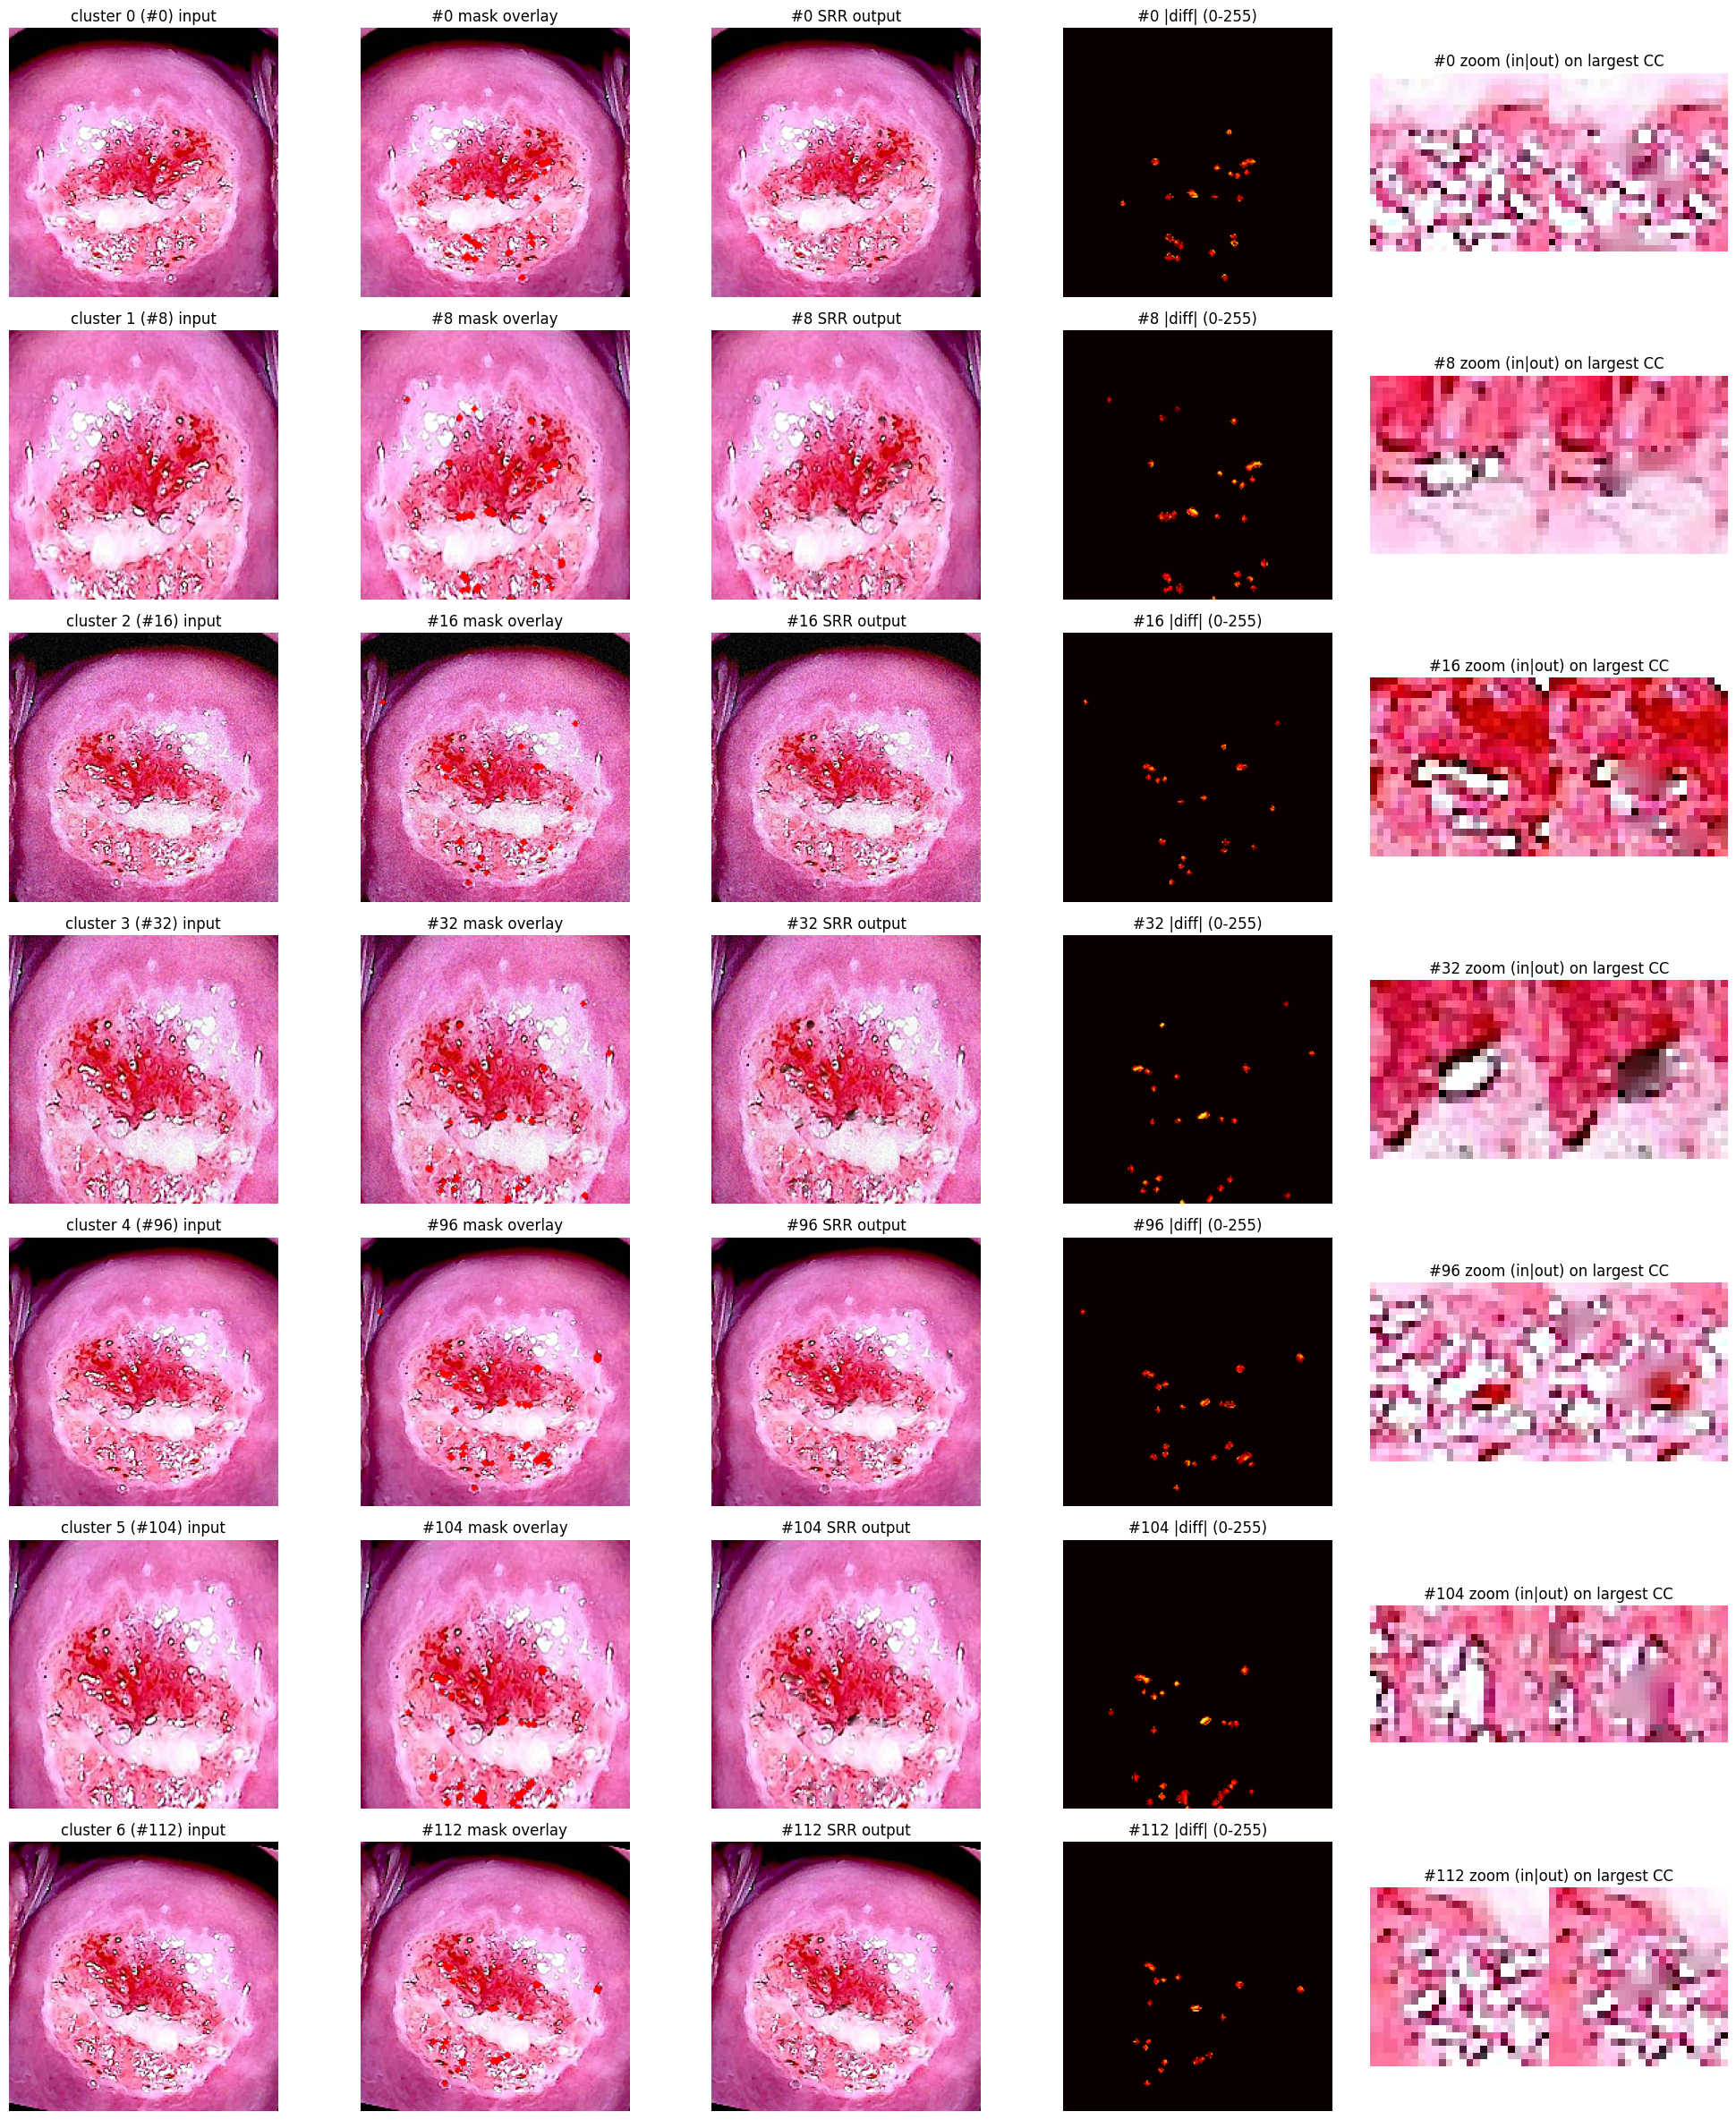

In [7]:
# ============================================================
# Visualise SRR: ONE FRAME PER CLUSTER (up to 7), 5 panels each:
#   Input | mask overlay | SRR output | |diff| (vmax=255) | zoom on largest CC
#   Tight layout. No matplotlib.use('Agg') inside functions.
#   Saved to results/srr_per_cluster.png
# ============================================================
def _largest_cc_center(mask):
    """Return (cy, cx, r) of the largest connected component in mask,
    or None if mask is empty."""
    if not mask.any():
        return None
    n_cc, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    if n_cc <= 1:
        return None
    # largest CC (skip background label 0)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    ys, xs = np.where(lab == k)
    if len(ys) == 0:
        return None
    cy, cx = int(ys.mean()), int(xs.mean())
    area = int(st[k, cv2.CC_STAT_AREA])
    r = max(8, int(math.sqrt(area / math.pi)) + 10)
    return cy, cx, r

def show_srr_per_cluster():
    """One frame per cluster, 5 panels each, saved to results/srr_per_cluster.png."""
    n = len(cluster_reps)
    fig, axes = plt.subplots(n, 5, figsize=(20, 3.4 * n))
    if n == 1:
        axes = axes[np.newaxis, :]
    for row, rep_i in enumerate(cluster_reps):
        i = int(rep_i)
        img_s  = X_sharp[i]
        out    = X_srr[i]
        ref_m  = X_srr_masks[i]
        # 1. Input (sharpened)
        axes[row, 0].imshow(img_s)
        axes[row, 0].set_title(f"cluster {row} (#{i}) input")
        # 2. Mask overlay (refined mask in red)
        ov = img_s.copy()
        ov[ref_m] = [255, 0, 0]
        axes[row, 1].imshow(ov)
        axes[row, 1].set_title(f"#{i} mask overlay")
        # 3. SRR output
        axes[row, 2].imshow(out)
        axes[row, 2].set_title(f"#{i} SRR output")
        # 4. |diff| with fixed scale vmax=255 (NO x4, NO saturation)
        diff = np.abs(out.astype(np.int32) - img_s.astype(np.int32)).mean(axis=2)
        axes[row, 3].imshow(diff, cmap='hot', vmin=0, vmax=255)
        axes[row, 3].set_title(f"#{i} |diff| (0-255)")
        # 5. Zoom crop on the LARGEST connected component of the mask
        ctr = _largest_cc_center(ref_m)
        if ctr is not None:
            cy, cx, r = ctr
            y0, y1 = max(0, cy - r), min(img_s.shape[0], cy + r)
            x0, x1 = max(0, cx - r), min(img_s.shape[1], cx + r)
            crop = np.concatenate([img_s[y0:y1, x0:x1],
                                   out[y0:y1, x0:x1]], axis=1)
            axes[row, 4].imshow(crop)
            axes[row, 4].set_title(f"#{i} zoom (in|out) on largest CC")
        else:
            axes[row, 4].imshow(img_s)
            axes[row, 4].set_title(f"#{i} no glare")
        for ax in axes[row]:
            ax.set_axis_off()
    plt.tight_layout()
    _fig_path = os.path.join(SAVE_DIR, 'srr_per_cluster.png')
    plt.savefig(_fig_path, dpi=100, bbox_inches='tight')
    print(f"Saved per-cluster figure -> {_fig_path}")
    plt.show()

show_srr_per_cluster()


In [8]:
# ============================================================
# Step 4.3 — srr_validator: 11 SRR metrics inside the FOV only.
#   'original' = reference (sharpened input X_base)
#   'processed' = SRR output
# ============================================================

def _vessel_map_green(img_rgb):
    """Frangi vessel filter on the GREEN channel -> vessel probability (0-1)."""
    green = img_rgb[..., 1].astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(green, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        gx = cv2.Sobel(green, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(green, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice_green(original, processed, fov_mask, top_pct=10):
    """Dice of top `top_pct` Frangi vessel pixels (GREEN channel) inside FOV.
    Dice = 2*|A∩B| / (|A|+|B|)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map_green(original)[f]
    v_p = _vessel_map_green(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum() + b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map (thresholds 50/150)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _immerkaer_noise(gray_float, mask):
    """Immerkaer noise sigma: MAD of the Laplacian response with the
    Immerkaer mask [[1,-2,1],[-2,4,-2],[1,-2,1]], scaled by sqrt(pi/6)*1.4826.
    """
    kernel = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    N = cv2.filter2D(gray_float, -1, kernel)
    vals = N[mask]
    if len(vals) < 10:
        return float('nan')
    med = np.median(vals)
    mad = np.median(np.abs(vals - med))
    return float(np.sqrt(np.pi / 6.0) * 1.4826 * mad)

def _mean_sat(img_rgb, fov_mask):
    """Mean HSV-S inside the FOV."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return float(hsv[..., 1][fov_mask].mean())

def _luma_entropy_bits(img_rgb, fov_mask):
    """Shannon entropy of the Y channel (YCrCb) inside the FOV, in bits/px (0-8)."""
    ycrcb = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
    Y = ycrcb[..., 0]
    vals = Y[fov_mask]
    if len(vals) < 10:
        return float('nan')
    hist, _ = np.histogram(vals, bins=256, range=(0, 256))
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def srr_validator(original, processed, fov_mask):
    """Compute 11 SRR metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                                   up
      m2  SSIM                                         up
      m3  DeltaE76 (mean of per-pixel CIE76, NOT RMS) down
      m4  a* correlation                               up
      m5  |a*| shift (mean |Δa*|)                     down
      m6  Vessel Dice (top-10% Frangi, green channel) up
      m7  Edge IoU (Canny 50/150)                      up
      m8  Sharpness ratio (Laplacian var, out/in)     neutral
      m9  Noise ratio (Immerkaer MAD-Laplacian, out/in) down
      m10 Saturation ratio (mean HSV-S, out/in)       neutral
      m11 Luma bits (Shannon entropy of Y of OUTPUT)  neutral (0-8 bits/px)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked, per-channel mean)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: DeltaE76 (mean of per-pixel CIE76, NOT RMS)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |a*| shift (mean |Δa*| per pixel)
    da = np.abs(lab_p[..., 1] - lab_o[..., 1])
    m5 = float(da[f].mean())
    # m6: Vessel Dice (top-10% Frangi on GREEN channel)
    m6 = _vessel_dice_green(original, processed, f, top_pct=10)
    # m7: Edge IoU (Canny 50/150)
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (Immerkaer MAD-Laplacian sigma, out/in)
    noise_o = _immerkaer_noise(g_o.astype(np.float32), f)
    noise_p = _immerkaer_noise(g_p.astype(np.float32), f)
    m9 = noise_p / max(noise_o, 1e-9)
    # m10: Saturation ratio (mean HSV-S, out/in)
    sat_o = _mean_sat(original, f)
    sat_p = _mean_sat(processed, f)
    m10 = sat_p / max(sat_o, 1e-9)
    # m11: Luma bits (Shannon entropy of Y channel of OUTPUT inside FOV)
    m11 = _luma_entropy_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (key, name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",          "fidelity",  "up"),
    ("m2",  "SSIM",               "fidelity",  "up"),
    ("m3",  "DeltaE76",           "colour",    "down"),
    ("m4",  "a* corr",            "colour",    "up"),
    ("m5",  "|a* shift|",        "colour",    "down"),
    ("m6",  "Vessel Dice",        "structure", "up"),
    ("m7",  "Edge IoU",           "structure", "up"),
    ("m8",  "Sharpness ratio",   "quality",   "neutral"),
    ("m9",  "Noise ratio",        "quality",   "down"),
    ("m10", "Saturation ratio",    "quality",   "neutral"),
    ("m11", "Luma bits",          "cost",      "neutral"),
]
METRIC_KEYS   = [m[0] for m in METRIC_META]
METRIC_NAMES  = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print(f"srr_validator ready: {len(METRIC_KEYS)} metrics (m1..m{len(METRIC_KEYS)}).")


srr_validator ready: 11 metrics (m1..m11).


In [9]:
# ============================================================
# Step 4.4 — Cluster-mean + cluster-bootstrap CI helpers.
#   Resample CLUSTERS (not images, not i % n_clusters).
#   WITHIN-PATIENT, NOT a population CI.
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=1000, seed=42):
    """Bootstrap CI over clusters (1000 resamples, resample clusters).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

print("Cluster-mean + cluster-bootstrap CI helpers ready (1000 resamples).")
print("  WITHIN-PATIENT, resample clusters (NOT images, NOT i % n_clusters).")


Cluster-mean + cluster-bootstrap CI helpers ready (1000 resamples).
  WITHIN-PATIENT, resample clusters (NOT images, NOT i % n_clusters).


In [10]:
# ============================================================
# Table A — All 128 frames, SRR vs input.
#   Cluster means + cluster bootstrap 95% CI (1000 resamples).
#   Writes results/results_SRR.csv + results/SRR_validation_table_A.csv.
#   Provenance: SRR_CONFIG_HASH + cache_hash added to every CSV.
#   Hard assert: no NaN in any of the 11 metric columns.
# ============================================================

# Delete stale CSVs from previous runs (in SAVE_DIR and CWD)
for _old in glob.glob(os.path.join(SAVE_DIR, "results_*.csv")) + \
             glob.glob(os.path.join(SAVE_DIR, "SRR_validation_table_*.csv")) + \
             glob.glob("results_*.csv") + glob.glob("SRR_validation_table_*.csv"):
    os.remove(_old)
print(f"Deleted stale results_*.csv and SRR_validation_table_*.csv.")

rows_a = []
for i in range(n_images):
    metrics = srr_validator(images[i], X_srr[i], fov[i])
    rows_a.append({
        "technique":       "SRR",
        "image_id":        image_id[i],
        "cluster_id":      int(cluster_ids[i]),
        "cache_hash":      cache_hash,
        "srr_config_hash": SRR_CONFIG_HASH,
        **metrics,
    })
df_a = pd.DataFrame(rows_a)
df_a.to_csv(os.path.join(SAVE_DIR, "results_SRR.csv"), index=False)
print(f"Wrote {SAVE_DIR}/results_SRR.csv ({len(df_a)} rows, {len(METRIC_KEYS)} metrics).")

# Hard assert: no NaN in any of the 11 metric columns
for mk in METRIC_KEYS:
    n_nan = int(df_a[mk].isna().sum())
    assert n_nan == 0, f"NaN in {mk}: {n_nan} (Table A). Check the validator."
print("No NaN values in any of the 11 metric columns (Table A).")

# Cluster-mean + bootstrap CI (1000 resamples, resample clusters)
agg_rows_a = []
_row = {"technique": "SRR", "cache_hash": cache_hash, "srr_config_hash": SRR_CONFIG_HASH}
for mk in METRIC_KEYS:
    mean, lo, hi = _cluster_bootstrap_ci(df_a, mk, n_boot=1000, seed=42)
    _row[mk]        = mean
    _row[f"{mk}_lo"] = lo
    _row[f"{mk}_hi"] = hi
agg_rows_a.append(_row)
agg_df_a = pd.DataFrame(agg_rows_a).set_index("technique")
agg_df_a.to_csv(os.path.join(SAVE_DIR, "SRR_validation_table_A.csv"))
print(f"Wrote {SAVE_DIR}/SRR_validation_table_A.csv")
print(f"  n_images = {n_images} | n_clusters = {n_clusters}")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")
print(f"  Table A measures ALTERATION (lower PSNR = more glare removed = NOT 'good').")


Deleted stale results_*.csv and SRR_validation_table_*.csv.
Wrote results/results_SRR.csv (128 rows, 11 metrics).
No NaN values in any of the 11 metric columns (Table A).
Wrote results/SRR_validation_table_A.csv
  n_images = 128 | n_clusters = 7
  WITHIN-PATIENT, 7 clusters, NOT a population CI.
  Table A measures ALTERATION (lower PSNR = more glare removed = NOT 'good').


In [11]:
# ============================================================
# Table B — SRR recovery (paired, FAIR test).
#   1. Compute the dilated refined real-glare mask for every frame.
#   2. Paste synthetic glare with VARIED radius (3-11px), softened edges,
#      tint 252-255 (all channels > SRR_V_THR=250 so the detector can
#      actually see it), on tissue that has no real glare.
#   3. Sharpen -> input. remove_specular(input, raw_with_glare, fov) -> out.
#   4. Score on scoring_fov = fov AND NOT dilated_refined_real_glare.
#   5. Recall split by tissue brightness:
#        - dark/mid (V < 220): ASSERT mean recall > 0.9.
#        - bright (V >= 220): report only (by design the ring test rejects
#          glare on bright tissue, so low recall here is correct).
#   6. Real false-positive rate on CLEAN frames (no paste): a real FP is a
#      pixel masked by the detector that is NOT in the dilated raw_mask.
#   7. Write Table B CSV FIRST, then warn (don't assert) so cell 13 prints.
#   Writes results/results_SRR_paired.csv + results/SRR_validation_table_B.csv.
# ============================================================

# Size bins for recall reporting (diameter in px)
SIZE_BINS = [(3, 5, "small (3-5)"), (6, 8, "medium (6-8)"), (9, 11, "large (9-11)")]

# Bright-tissue threshold (splits dark/mid vs bright tissue for recall reporting)
BRIGHT_TISSUE_V = 220


def _paste_synthetic_glare_fair(img, fov, rng, avoid_mask=None, n_blobs=None):
    """Paste 1-3 synthetic glare dots with VARIED radius (3-11px), softened
    edges, and a slight tint. Tint is 252-255 per channel so ALL channels
    are > SRR_V_THR (250) — by definition glare (the v1 245-255 tint gave
    ~16% of blobs a max channel <=250, which the detector cannot see).
    Returns (img_glared, glare_truth, blob_radii, blob_centers).
    """
    H, W = img.shape[:2]
    fov_area = float(fov.sum())
    max_blob_r = max(3, int(np.sqrt(SRR_MAX_BLOB_FRAC * fov_area / np.pi)))
    max_blob_r = min(max_blob_r, 11)
    out = img.copy()
    gmask = np.zeros((H, W), dtype=bool)
    blob_radii = []
    blob_centers = []
    candidates = fov.copy()
    if avoid_mask is not None:
        candidates = candidates & ~avoid_mask
    ys, xs = np.where(candidates)
    if len(ys) == 0:
        return out, gmask, blob_radii, blob_centers
    n = n_blobs if n_blobs else int(rng.integers(1, 4))
    for _ in range(n):
        idx = int(rng.integers(0, len(ys)))
        cy, cx = int(ys[idx]), int(xs[idx])
        r = int(rng.integers(3, max(4, max_blob_r + 1)))
        blob_radii.append(r)
        blob_centers.append((cy, cx))
        # Tint 252-255 so ALL channels > SRR_V_THR (250) — by definition glare.
        tint = np.array([rng.integers(252, 256), rng.integers(252, 256),
                         rng.integers(252, 256)], dtype=np.uint8)
        blob_layer = np.zeros((H, W), dtype=np.uint8)
        cv2.circle(blob_layer, (cx, cy), r, 255, -1)
        blob_layer = cv2.GaussianBlur(blob_layer, (5, 5), 1.0)
        blob_mask_soft = blob_layer > 128
        for ch in range(3):
            out[..., ch] = np.where(blob_mask_soft, tint[ch], out[..., ch])
        yy, xx = np.ogrid[:H, :W]
        disk = (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2
        gmask |= disk & fov
    return out, gmask, blob_radii, blob_centers


# ---- Compute the dilated refined real-glare mask for every frame ----
real_glare_refined = []
for i in range(n_images):
    _, _, ref_m = remove_specular(images[i], images_raw[i], fov[i])
    real_glare_refined.append(ref_m)
n_with_real_glare = int(sum(1 for m in real_glare_refined if m.any()))
n_clean = n_images - n_with_real_glare
print(f"Frames with 0 real glare on clean frame: {n_clean}/{n_images}")
print(f"Frames with real glare (will exclude refined mask from scoring): {n_with_real_glare}/{n_images}")

# ---- Real false-positive rate on CLEAN frames (no paste) ----
# A real FP = a pixel masked by the detector that is NOT in the dilated
# raw_mask. (The v1 "acetowhite FP" label was inverted — it counted
# pasted-glare pixels on bright tissue that got masked, which are CORRECT
# detections, not false positives.)
real_fp_total = 0
real_refined_total = 0
_k_dil_fp = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
for i in range(n_images):
    raw_m = X_srr_raw[i]
    ref_m = X_srr_masks[i] & fov[i]
    # Dilate raw_mask by (close + dilate) iterations to allow for the
    # intentional expansion of refined beyond raw.
    raw_dilated = cv2.dilate(raw_m.astype(np.uint8), _k_dil_fp,
                              iterations=SRR_DILATE + 2).astype(bool)
    spurious = ref_m & ~raw_dilated & fov[i]
    real_fp_total += int(spurious.sum())
    real_refined_total += int(ref_m.sum())
real_fp_rate = real_fp_total / max(real_refined_total, 1)
print(f"\n[Table B real-FP] on clean frames: spurious mask px = {real_fp_total} / "
      f"total refined mask px = {real_refined_total} ({real_fp_rate*100:.2f}%)")
print("  (a real FP = a pixel masked by the detector that is NOT in the")
print("   dilated raw_mask; high rate means the detector is masking tissue")
print("   that is not even a glare candidate — inspect the per-cluster figure.)")

# ---- Table B paired paste-and-recover ----
rng_b = np.random.default_rng(SEED)
rows_b = []
all_recalls = []
all_residuals = []
all_recalls_dark = []    # V < 220 tissue (assert target)
all_recalls_bright = []  # V >= 220 tissue (report only)
for i in range(n_images):
    real_refined = real_glare_refined[i]
    img_raw_glared, glare_truth, blob_radii, blob_centers = _paste_synthetic_glare_fair(
        images_raw[i], fov[i], rng_b, avoid_mask=real_refined)
    img_sharp_glared = sharpen(img_raw_glared)
    out, _, ref_m = remove_specular(img_sharp_glared, img_raw_glared, fov[i])
    scoring_fov = fov[i] & ~real_refined
    if not scoring_fov.any():
        continue
    metrics = srr_validator(images[i], out, scoring_fov)
    rows_b.append({
        "technique":       "SRR_recovery",
        "image_id":        image_id[i],
        "cluster_id":      int(cluster_ids[i]),
        "cache_hash":      cache_hash,
        "srr_config_hash": SRR_CONFIG_HASH,
        **metrics,
    })
    # Recall split by tissue brightness (using the UN-SHARPENED image's V,
    # the same image the detector sees).
    truth = glare_truth & fov[i]
    detected = ref_m & truth
    hsv_raw = cv2.cvtColor(images_raw[i], cv2.COLOR_RGB2HSV)
    V_raw = hsv_raw[..., 2]
    truth_dark = truth & (V_raw < BRIGHT_TISSUE_V)
    truth_bright = truth & (V_raw >= BRIGHT_TISSUE_V)
    if truth.sum() > 0:
        recall = float(detected.sum()) / float(truth.sum())
        all_recalls.append(recall)
    if truth_dark.sum() > 0:
        rec_dark = float((ref_m & truth_dark).sum()) / float(truth_dark.sum())
        all_recalls_dark.append(rec_dark)
    if truth_bright.sum() > 0:
        rec_bright = float((ref_m & truth_bright).sum()) / float(truth_bright.sum())
        all_recalls_bright.append(rec_bright)
    # Residual glare fraction (on the pasted-truth region)
    hsv_out = cv2.cvtColor(out, cv2.COLOR_RGB2HSV)
    residual_glare = int(((hsv_out[..., 2] > SRR_V_THR) &
                           (hsv_out[..., 1] < SRR_S_THR) & truth).sum())
    if truth.sum() > 0:
        residual_frac = float(residual_glare) / float(truth.sum())
        all_residuals.append(residual_frac)

# ---- Per-size-bin recall (one fair-paste blob per frame per bin) ----
# tint = 252 (was 250 in v1, which the detector cannot see since V > 250 is required)
print("\n[Table B] recall per size bin (diagnostic, one fair-paste blob per frame):")
print("  tint = 252 (all channels > SRR_V_THR=250, so the detector CAN see it)")
for rmin, rmax, label in SIZE_BINS:
    bin_recalls = []
    for i in range(n_images):
        real_refined = real_glare_refined[i]
        rng_diag = np.random.default_rng(SEED + rmin * 100 + i)
        r_fix = (rmin + rmax) // 2
        img_raw2 = images_raw[i].copy()
        candidates = fov[i] & ~real_refined
        ys, xs = np.where(candidates)
        if len(ys) == 0:
            continue
        idx = int(rng_diag.integers(0, len(ys)))
        cy, cx = int(ys[idx]), int(xs[idx])
        blob_layer = np.zeros(img_raw2.shape[:2], dtype=np.uint8)
        cv2.circle(blob_layer, (cx, cy), r_fix, 255, -1)
        blob_layer = cv2.GaussianBlur(blob_layer, (5, 5), 1.0)
        blob_mask_soft = blob_layer > 128
        # tint = 252 so all 3 channels > SRR_V_THR (250)
        tint = np.array([252, 252, 252], dtype=np.uint8)
        for ch in range(3):
            img_raw2[..., ch] = np.where(blob_mask_soft, tint[ch], img_raw2[..., ch])
        yy, xx = np.ogrid[:img_raw2.shape[0], :img_raw2.shape[1]]
        truth2 = ((yy - cy) ** 2 + (xx - cx) ** 2 <= r_fix ** 2) & fov[i]
        img_sharp2 = sharpen(img_raw2)
        out2, _, ref_m2 = remove_specular(img_sharp2, img_raw2, fov[i])
        if truth2.sum() > 0:
            rec = float((ref_m2 & truth2).sum()) / float(truth2.sum())
            bin_recalls.append(rec)
    if bin_recalls:
        print(f"  {label}: recall = {np.mean(bin_recalls):.4f} (n={len(bin_recalls)})")
    else:
        print(f"  {label}: no frames")

# ---- Recall split by tissue brightness ----
mean_recall_dark  = float(np.mean(all_recalls_dark))  if all_recalls_dark  else float('nan')
mean_recall_bright= float(np.mean(all_recalls_bright))if all_recalls_bright else float('nan')
print(f"\n[Table B recall by tissue brightness]:")
print(f"  dark/mid tissue (V < {BRIGHT_TISSUE_V}):  recall = {mean_recall_dark:.4f} "
      f"(n={len(all_recalls_dark)} frames; ASSERT > 0.9)")
print(f"  bright tissue (V >= {BRIGHT_TISSUE_V}):    recall = {mean_recall_bright:.4f} "
      f"(n={len(all_recalls_bright)} frames; REPORT ONLY — by design the ring")
print(f"                                                   test rejects glare on bright tissue)")

# ---- Sanity line: overall recall + residual ----
mean_recall    = float(np.mean(all_recalls)) if all_recalls else float('nan')
mean_residual  = float(np.mean(all_residuals)) if all_residuals else float('nan')
print(f"\n[Table B sanity] frames scored: {len(rows_b)}/{n_images}")
print(f"[Table B sanity] detector recall on pasted mask (all sizes, all tissue): {mean_recall:.4f}")
print(f"[Table B sanity] residual glare fraction:                                  {mean_residual:.4f}")
assert len(rows_b) > 0, "Table B has 0 scored frames (all frames fully real glare)."

# ---- Write Table B CSV FIRST, then warn (don't assert) so cell 13 prints ----
df_b = pd.DataFrame(rows_b)
df_b.to_csv(os.path.join(SAVE_DIR, "results_SRR_paired.csv"), index=False)
print(f"\nWrote {SAVE_DIR}/results_SRR_paired.csv ({len(df_b)} rows).")

# Hard assert: no NaN in any of the 11 metric columns
for mk in METRIC_KEYS:
    n_nan = int(df_b[mk].isna().sum())
    assert n_nan == 0, f"NaN in {mk}: {n_nan} (Table B). Check the validator."
print("No NaN values in any of the 11 metric columns (Table B).")

# Cluster-mean + bootstrap CI (1000 resamples, resample clusters)
agg_rows_b = []
_row = {"technique": "SRR_recovery", "cache_hash": cache_hash, "srr_config_hash": SRR_CONFIG_HASH}
for mk in METRIC_KEYS:
    mean, lo, hi = _cluster_bootstrap_ci(df_b, mk, n_boot=1000, seed=42)
    _row[mk]        = mean
    _row[f"{mk}_lo"] = lo
    _row[f"{mk}_hi"] = hi
agg_rows_b.append(_row)
agg_df_b = pd.DataFrame(agg_rows_b).set_index("technique")
agg_df_b.to_csv(os.path.join(SAVE_DIR, "SRR_validation_table_B.csv"))
print(f"Wrote {SAVE_DIR}/SRR_validation_table_B.csv")

# ---- Recall warning (AFTER CSV write, so cell 13 always prints) ----
if not all_recalls_dark or np.isnan(mean_recall_dark):
    print(f"\n[WARNING] no dark/mid-tissue pasted blobs to evaluate (n=0). "
          f"Cannot assert recall. Inspect the per-cluster figure.")
elif mean_recall_dark < 0.9:
    print(f"\n[WARNING] dark/mid-tissue recall {mean_recall_dark:.4f} <= 0.9. "
          f"SRR detector may be failing on synthetic glare. Inspect the "
          f"per-bin recall above and the threshold sweep CSV before quoting "
          f"Table B. Tables will still print in the next cell.")
else:
    print(f"\n[Table B] dark/mid-tissue recall > 0.9: PASSED.")


Frames with 0 real glare on clean frame: 0/128
Frames with real glare (will exclude refined mask from scoring): 128/128

[Table B real-FP] on clean frames: spurious mask px = 0 / total refined mask px = 53520 (0.00%)
  (a real FP = a pixel masked by the detector that is NOT in the
   dilated raw_mask; high rate means the detector is masking tissue
   that is not even a glare candidate — inspect the per-cluster figure.)

[Table B] recall per size bin (diagnostic, one fair-paste blob per frame):
  tint = 252 (all channels > SRR_V_THR=250, so the detector CAN see it)
  small (3-5): recall = 0.3213 (n=128)
  medium (6-8): recall = 0.2969 (n=128)
  large (9-11): recall = 0.2969 (n=128)

[Table B recall by tissue brightness]:
  dark/mid tissue (V < 220):  recall = 0.5782 (n=125 frames; ASSERT > 0.9)
  bright tissue (V >= 220):    recall = 0.2394 (n=117 frames; REPORT ONLY — by design the ring
                                                   test rejects glare on bright tissue)

[Table B sa

In [12]:
# ============================================================
# Threshold sweep — sensitivity of mask coverage and residual glare
#   to the V threshold (235-250) and ring-contrast threshold (15-40).
#   Writes results/SRR_threshold_sweep.csv (NOT part of the tables).
#   Shows how sensitive the chosen (V_thr=250, ring_contrast=30) result is.
# ============================================================
V_GRID    = list(range(235, 251))         # 235..250 (16 values)
RING_GRID = list(range(15, 41, 5))        # 15, 20, 25, 30, 35, 40 (6 values)


def _glare_count(im, fov_mask, v_thr):
    """Count glare pixels (V>v_thr & S<S_THR) inside the FOV."""
    hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
    return int(((hsv[..., 2] > v_thr) & (hsv[..., 1] < SRR_S_THR) & fov_mask).sum())


def _srr_sweep_once(v_thr, ring_contrast):
    """Run remove_specular on all frames with overridden V_THR and
    ring-contrast. Returns (X_srr_local, masks_local)."""
    global SRR_V_THR, SRR_RING_CONTRAST
    _old_v, _old_r = SRR_V_THR, SRR_RING_CONTRAST
    SRR_V_THR = v_thr
    SRR_RING_CONTRAST = ring_contrast
    try:
        outs   = np.empty_like(X_sharp)
        masks  = np.zeros((n_images, IMG_SIZE, IMG_SIZE), dtype=bool)
        for i in range(n_images):
            out, _, ref_m = remove_specular(X_sharp[i], X_unsharp[i], fov[i])
            outs[i]   = out
            masks[i]  = ref_m
    finally:
        SRR_V_THR = _old_v
        SRR_RING_CONTRAST = _old_r
    return outs, masks


sweep_rows = []
_total = len(V_GRID) * len(RING_GRID)
_done = 0
print(f"Threshold sweep: {_total} configs ({len(V_GRID)} V x {len(RING_GRID)} ring) ...")
for v_thr in V_GRID:
    for ring_c in RING_GRID:
        outs, masks = _srr_sweep_once(v_thr, ring_c)
        cov = float(masks.mean(axis=(1, 2)).mean())
        before = sum(_glare_count(X_unsharp[i], fov[i], v_thr) for i in range(n_images))
        after  = sum(_glare_count(outs[i],       fov[i], v_thr) for i in range(n_images))
        resid  = after / max(before, 1)
        sweep_rows.append({
            "V_thr": v_thr, "ring_contrast": ring_c,
            "mask_coverage_frac": cov,
            "glare_before": before, "glare_after": after,
            "residual_frac": resid,
            "cache_hash": cache_hash, "srr_config_hash": SRR_CONFIG_HASH,
        })
        _done += 1
        if _done % 8 == 0:
            print(f"  {_done}/{_total} configs done")

df_sweep = pd.DataFrame(sweep_rows)
df_sweep.to_csv(os.path.join(SAVE_DIR, "SRR_threshold_sweep.csv"), index=False)
print(f"\nWrote {SAVE_DIR}/SRR_threshold_sweep.csv ({len(df_sweep)} rows).")

# Pivot tables for a quick visual sense of sensitivity
print("\nMask coverage (% of FOV) — rows: V_thr, cols: ring_contrast:")
_piv_cov = df_sweep.pivot(index="V_thr", columns="ring_contrast", values="mask_coverage_frac") * 100
print(_piv_cov.round(3).to_string())
print("\nResidual glare (% of before) — rows: V_thr, cols: ring_contrast:")
_piv_res = df_sweep.pivot(index="V_thr", columns="ring_contrast", values="residual_frac") * 100
print(_piv_res.round(2).to_string())
print("\n  The chosen config (V_thr=250, ring_contrast=30) is at row 250, col 30.")
print("  Large jumps across the row or column mean the result is sensitive to")
print("  that threshold; a flat plateau means it is robust.")


Threshold sweep: 96 configs (16 V x 6 ring) ...
  8/96 configs done
  16/96 configs done
  24/96 configs done
  32/96 configs done
  40/96 configs done
  48/96 configs done
  56/96 configs done
  64/96 configs done
  72/96 configs done
  80/96 configs done
  88/96 configs done
  96/96 configs done

Wrote results/SRR_threshold_sweep.csv (96 rows).

Mask coverage (% of FOV) — rows: V_thr, cols: ring_contrast:
ring_contrast     15     20     25     30     35     40
V_thr                                                  
235            3.520  2.587  1.826  1.263  0.876  0.652
236            3.596  2.577  1.811  1.276  0.884  0.652
237            3.590  2.563  1.822  1.268  0.897  0.659
238            3.589  2.596  1.813  1.258  0.887  0.663
239            3.561  2.610  1.815  1.262  0.880  0.663
240            3.570  2.609  1.827  1.279  0.881  0.668
241            3.588  2.618  1.842  1.287  0.891  0.671
242            3.596  2.624  1.820  1.293  0.892  0.667
243            3.608  2.638  

In [13]:
# ============================================================
# Hand-labelled recall & precision on ~10 real frames.
#   With no labels you cannot report recall or precision against ground
#   truth — only the paired-glare proxy in Table B. This cell loads an
#   OPTIONAL hand-labelled JSON and reports per-frame recall/precision.
#
#   JSON file: results/SRR_hand_labels.json
#   Format:    {"img_0007": [[y1, x1, y2, x2], ...],   # bounding boxes
#               "img_0019": [...], ...}
#   Coordinates are in 200x200 image space (the same as the masks in
#   results/masks/). Label what a human would call GLARE on the
#   UN-SHARPENED frame.
# ============================================================
import json as _json

# Pick ~10 frames: one per cluster (7) + 3 more from the largest cluster.
HANDPICK_INDICES = []
_seen_clusters = set()
for i in range(n_images):
    c = int(cluster_ids[i])
    if c not in _seen_clusters:
        HANDPICK_INDICES.append(i)
        _seen_clusters.add(c)
    if len(HANDPICK_INDICES) >= 7:
        break
_uc, _counts = np.unique(cluster_ids, return_counts=True)
_biggest_c = int(_uc[int(np.argmax(_counts))])
_extra = [i for i in range(n_images)
          if int(cluster_ids[i]) == _biggest_c and i not in HANDPICK_INDICES][:3]
HANDPICK_INDICES.extend(_extra)
print(f"Hand-labelling target frames ({len(HANDPICK_INDICES)}):")
for i in HANDPICK_INDICES:
    print(f"  {image_id[i]}  (cluster {int(cluster_ids[i])}, "
          f"mask coverage {float(X_srr_masks[i].mean())*100:.2f}%)")

HAND_LABELS_PATH = os.path.join(SAVE_DIR, "SRR_hand_labels.json")
if not os.path.exists(HAND_LABELS_PATH):
    print(f"\n[hand-labels] {HAND_LABELS_PATH} not found.")
    print("  To enable hand-labelled recall/precision:")
    print("  1. For each target frame above, open the un-sharpened frame in")
    print("     your labelling tool (or use the saved PNG in results/srr_outputs/).")
    print("  2. Draw bounding boxes around the regions a human would call")
    print("     GLARE (bright white specular pools, NOT acetowhite).")
    print("  3. Save as JSON:")
    print('       {"img_0007": [[y1,x1,y2,x2], [y1,x1,y2,x2], ...],')
    print('        "img_0019": [...], ...}')
    print("  4. Re-run this cell. With no labels, recall/precision against")
    print("     ground truth CANNOT be reported — only the paired-glare proxy.")
else:
    with open(HAND_LABELS_PATH, "r") as _f:
        hand_labels = _json.load(_f)
    print(f"\n[hand-labels] loaded {len(hand_labels)} frames from {HAND_LABELS_PATH}")
    rows_h = []
    for i in HANDPICK_INDICES:
        iid = str(image_id[i])
        if iid not in hand_labels:
            print(f"  {iid}: no label in JSON — skipping.")
            continue
        boxes = hand_labels[iid]
        truth = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
        for box in boxes:
            y1, x1, y2, x2 = box
            truth[max(0, y1):y2, max(0, x1):x2] = True
        truth = truth & fov[i]
        pred  = X_srr_masks[i] & fov[i]
        tp = int((truth &  pred).sum())
        fn = int((truth & ~pred).sum())
        fp = int((~truth &  pred).sum())
        recall    = tp / max(tp + fn, 1)
        precision = tp / max(tp + fp, 1)
        rows_h.append({
            "image_id": iid, "cluster_id": int(cluster_ids[i]),
            "tp": tp, "fn": fn, "fp": fp,
            "recall": recall, "precision": precision,
            "cache_hash": cache_hash, "srr_config_hash": SRR_CONFIG_HASH,
        })
        print(f"  {iid}: recall={recall:.3f}, precision={precision:.3f} "
              f"(tp={tp}, fn={fn}, fp={fp})")
    if rows_h:
        df_h = pd.DataFrame(rows_h)
        df_h.to_csv(os.path.join(SAVE_DIR, "SRR_hand_label_metrics.csv"), index=False)
        _mean_rec  = df_h["recall"].mean()
        _mean_prec = df_h["precision"].mean()
        print(f"\n[hand-labels] mean recall = {_mean_rec:.3f}, "
              f"mean precision = {_mean_prec:.3f} over {len(df_h)} frames.")
        print(f"  Wrote {SAVE_DIR}/SRR_hand_label_metrics.csv")
        print("  NOTE: hand labels are for ONE patient only; do not generalise.")
    else:
        print("\n[hand-labels] JSON loaded but no target frames matched. "
              "Check that image_id keys in the JSON match the printed ids above.")


Hand-labelling target frames (10):
  img_0000  (cluster 0, mask coverage 1.10%)
  img_0008  (cluster 1, mask coverage 1.38%)
  img_0016  (cluster 2, mask coverage 0.76%)
  img_0032  (cluster 3, mask coverage 1.00%)
  img_0096  (cluster 4, mask coverage 1.23%)
  img_0104  (cluster 5, mask coverage 1.44%)
  img_0112  (cluster 6, mask coverage 0.82%)
  img_0017  (cluster 2, mask coverage 0.76%)
  img_0018  (cluster 2, mask coverage 0.76%)
  img_0019  (cluster 2, mask coverage 0.76%)

[hand-labels] results\SRR_hand_labels.json not found.
  To enable hand-labelled recall/precision:
  1. For each target frame above, open the un-sharpened frame in
     your labelling tool (or use the saved PNG in results/srr_outputs/).
  2. Draw bounding boxes around the regions a human would call
     GLARE (bright white specular pools, NOT acetowhite).
  3. Save as JSON:
       {"img_0007": [[y1,x1,y2,x2], [y1,x1,y2,x2], ...],
        "img_0019": [...], ...}
  4. Re-run this cell. With no labels, recall/pre

In [14]:
# ============================================================
# Print Table A and Table B (11 columns each).
#   This cell ALWAYS runs (Table B's recall check is a warning, not a hard
#   stop), so the tables always print.
# ============================================================
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

def _format_table(agg_df, label, interpretation_note=""):
    """Print a 1-row table with cluster-mean [95% CI] per metric."""
    print("=" * 110)
    print(f"{label}")
    print(f"  cluster-weighted mean [95% CI]; WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI")
    print(f"  n_images = {n_images} | n_clusters = {n_clusters}")
    if interpretation_note:
        print(f"  NOTE: {interpretation_note}")
    print("=" * 110)
    row = {}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[agg_df.index[0], mk]
        lo   = agg_df.loc[agg_df.index[0], f"{mk}_lo"]
        hi   = agg_df.loc[agg_df.index[0], f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.4f} [{lo:.4f}, {hi:.4f}]"
    df_print = pd.DataFrame([row], index=agg_df.index)
    arrow_map = {"up": "^", "down": "v", "neutral": "o"}
    headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
               for mk in METRIC_KEYS}
    print(df_print.rename(columns=headers).to_string())
    print()

_format_table(agg_df_a, "TABLE A — SRR vs input (all frames, SRR output vs sharpened input)",
              interpretation_note="Table A measures ALTERATION. Lower PSNR = more glare removed. NOT a quality score.")
_format_table(agg_df_b, "TABLE B — SRR recovery (paired, synthetic glare pasted on un-sharpened)",
              interpretation_note="Recovery PSNR is provisional until dark/mid-tissue recall and real-FP rate are inspected.")

print("=" * 110)
print("FILES WRITTEN (under results/):")
print("  results/results_SRR.csv             — per-image Table A rows (11 metrics + provenance)")
print("  results/results_SRR_paired.csv      — per-image Table B rows (11 metrics + provenance)")
print("  results/SRR_validation_table_A.csv  — cluster-mean + 95% CI for Table A")
print("  results/SRR_validation_table_B.csv  — cluster-mean + 95% CI for Table B")
print("  results/SRR_threshold_sweep.csv    — V_thr x ring_contrast sweep (NOT a table)")
print("  results/SRR_hand_label_metrics.csv  — hand-labelled recall/precision (optional, ~10 frames)")
print("  results/srr_outputs/               — 128 SRR-output PNGs")
print("  results/masks/                      — 128 SRR-mask PNGs")
print("  results/srr_per_cluster.png         — one-frame-per-cluster figure")
print("=" * 110)
print("Provenance: every CSV has cache_hash (input images) + srr_config_hash (SRR config).")


TABLE A — SRR vs input (all frames, SRR output vs sharpened input)
  cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI
  n_images = 128 | n_clusters = 7
  NOTE: Table A measures ALTERATION. Lower PSNR = more glare removed. NOT a quality score.
                        PSNR (dB) (^)                 SSIM (^)             DeltaE76 (v)              a* corr (^)           |a* shift| (v)          Vessel Dice (^)             Edge IoU (^)      Sharpness ratio (o)          Noise ratio (v)     Saturation ratio (o)            Luma bits (o)
technique                                                                                                                                                                                                                                                                                      
SRR        27.9299 [27.4589, 28.4907]  0.9845 [0.9831, 0.9863]  0.4773 [0.4210, 0.5248]  0.9832 [0.9808, 0.9859]  0.2589 [0.2258, 0.2870]  0.9406 [0.9